<a href="https://colab.research.google.com/github/annkupina/ml_course_hw/blob/main/Anna_Kupina_HW_2_4_kNN_%D0%9A%D1%80%D0%BE%D1%81%D0%B2%D0%B0%D0%BB%D1%96%D0%B4%D0%B0%D1%86%D1%96%D1%8F_%D1%96_%D1%82%D1%8E%D0%BD%D0%B8%D0%BD%D0%B3_%D0%B3%D1%96%D0%BF%D0%B5%D1%80%D0%BF%D0%B0%D1%80%D0%B0%D0%BC%D0%B5%D1%82%D1%80%D1%96%D0%B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

В цьому домашньому завданні ми знову працюємо з даними з нашого змагання ["Bank Customer Churn Prediction (DLU Course)"](https://www.kaggle.com/t/7c080c5d8ec64364a93cf4e8f880b6a0).

Тут ми побудуємо рішення задачі класифікації з використанням kNearestNeighboors, знайдемо оптимальні гіперпараметри для цього методу і зробимо базові ансамблі. Це дасть змогу порівняти перформанс моделі з попередніми вивченими методами.

0. Зчитайте дані `train.csv` та зробіть препроцесинг використовуючи написаний Вами скрипт `process_bank_churn.py` так, аби в результаті отримати дані в розбитті X_train, train_targets, X_val, val_targets для експериментів.

  Якщо Вам не вдалось реалізувати в завданні `2.3. Дерева прийняття рішень` скрипт `process_bank_churn.py` - можна скористатись готовим скриптом з запропонованого рішення того завдання.

In [10]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier

In [3]:
raw_df = pd.read_csv('train.csv')

In [6]:
from process_bank_churn import preprocess_data

X_train, train_targets, X_val, val_targets, input_cols, scaler, encoder = preprocess_data(raw_df, scaler_numeric = False)

1. Навчіть на цих даних класифікатор kNN з параметрами за замовченням і виміряйте точність з допомогою AUROC на тренувальному та валідаційному наборах. Зробіть заключення про отриману модель: вона хороша/погана, чи є high bias/high variance?

In [13]:
knn = KNeighborsClassifier()
knn.fit(X_train, train_targets)

KNeighborsClassifier()

In [15]:
from sklearn.metrics import roc_auc_score

train_probs = knn.predict_proba(X_train)[:, 1]
val_probs = knn.predict_proba(X_val)[:, 1]

train_auc = roc_auc_score(train_targets, train_probs)
val_auc = roc_auc_score(val_targets, val_probs)

print(f'Train AUC: {train_auc:.4f}')
print(f'Validation AUC: {val_auc:.4f}')

Train AUC: 0.8226
Validation AUC: 0.5649


Погана модель, є high variance.

2. Використовуючи `GridSearchCV` знайдіть оптимальне значення параметра `n_neighbors` для класифікатора `kNN`. Псотавте крос валідацію на 5 фолдів.

  Після успішного завершення пошуку оптимального гіперпараметра
    - виведіть найкраще значення параметра
    - збережіть в окрему змінну `knn_best` найкращу модель, знайдену з `GridSearchCV`
    - оцініть якість передбачень  `knn_best` на тренувальній і валідаційній вибірці з допомогою AUROC.
    - зробіть висновок про якість моделі. Чи стала вона краще порівняно з попереднім пукнтом (2) цього завдання? Чи є вона краще за дерево прийняття рішень з попереднього ДЗ?

In [53]:
knn = KNeighborsClassifier()
params_knn = {'n_neighbors': np.arange(1, 25)}
knn_gs = GridSearchCV(knn, params_knn, cv=5)
knn_gs.fit(X_train, train_targets)

GridSearchCV(cv=5, estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
       18, 19, 20, 21, 22, 23, 24])})

In [54]:
knn_best = knn_gs.best_estimator_

In [55]:
train_probs = knn_best.predict_proba(X_train)[:, 1]
val_probs = knn_best.predict_proba(X_val)[:, 1]

train_auc = roc_auc_score(train_targets, train_probs)
val_auc = roc_auc_score(val_targets, val_probs)

print(f'Train AUC: {train_auc:.4f}')
print(f'Validation AUC: {val_auc:.4f}')

Train AUC: 0.7029
Validation AUC: 0.5869


Ця модель трохи краща за попередню, адже показала вище точність на валідаційній вибірці, але це все одно не дуже хороша модель.

Дерево прийняття рішень має суттєво вище точність (Train AUC: 0.9344, Validation AUC: 0.9142).

3. Виконайте пошук оптимальних гіперпараметрів для `DecisionTreeClassifier` з `GridSearchCV` за сіткою параметрів
  - `max_depth` від 1 до 20 з кроком 2
  - `max_leaf_nodes` від 2 до 10 з кроком 1

  Обовʼязково при цьому ініціюйте модель з фіксацією `random_state`.

  Поставте кросвалідацію на 3 фолди, `scoring='roc_auc'`, та виміряйте, скільки часу потребує пошук оптимальних гіперпараметрів.

  Після успішного завершення пошуку оптимальних гіперпараметрів
    - виведіть найкращі значення параметра
    - збережіть в окрему змінну `dt_best` найкращу модель, знайдену з `GridSearchCV`
    - оцініть якість передбачень  `dt_best` на тренувальній і валідаційній вибірці з допомогою AUROC.
    - зробіть висновок про якість моделі. Чи ця модель краща за ту, що ви знайшли вручну?

In [56]:
from sklearn.tree import DecisionTreeClassifier

In [58]:
%%time
model = DecisionTreeClassifier(random_state=42)
params = [
    {'max_depth': np.arange(1, 21, 2)},
    {'max_leaf_nodes': np.arange(2, 11, 1)}
]
model_gs = GridSearchCV(model, params, scoring='roc_auc', cv=3)
model_gs.fit(X_train, train_targets)

CPU times: user 1.77 s, sys: 0 ns, total: 1.77 s
Wall time: 1.78 s


GridSearchCV(cv=3, estimator=DecisionTreeClassifier(random_state=42),
             param_grid=[{'max_depth': array([ 1,  3,  5,  7,  9, 11, 13, 15, 17, 19])},
                         {'max_leaf_nodes': array([ 2,  3,  4,  5,  6,  7,  8,  9, 10])}],
             scoring='roc_auc')

In [59]:
dt_best = model_gs.best_estimator_

In [60]:
train_probs = dt_best.predict_proba(X_train)[:, 1]
val_probs = dt_best.predict_proba(X_val)[:, 1]

train_auc = roc_auc_score(train_targets, train_probs)
val_auc = roc_auc_score(val_targets, val_probs)

print(f'Train AUC: {train_auc:.4f}')
print(f'Validation AUC: {val_auc:.4f}')

Train AUC: 0.9263
Validation AUC: 0.9107


Ця модель (Train AUC: 0.9263, Validation AUC: 0.9107) трохи гірше в порівняння з тією, що знайдена вручну (Train AUC: 0.9344, Validation AUC: 0.9142).

4. Виконайте пошук оптимальних гіперпараметрів для `DecisionTreeClassifier` з `RandomizedSearchCV` за заданою сіткою параметрів і кількість ітерацій 40.

  Поставте кросвалідацію на 3 фолди, `scoring='roc_auc'`, зафіксуйте `random_seed` процедури крос валідації та виміряйте, скільки часу потребує пошук оптимальних гіперпараметрів.

  Після успішного завершення пошуку оптимальних гіперпараметрів
    - виведіть найкращі значення параметра
    - збережіть в окрему змінну `dt_random_search_best` найкращу модель, знайдену з `RandomizedSearchCV`
    - оцініть якість передбачень  `dt_random_search_best` на тренувальній і валідаційній вибірці з допомогою AUROC.
    - зробіть висновок про якість моделі. Чи ця модель краща за ту, що ви знайшли з `GridSearch`?
    - проаналізуйте параметри `dt_random_search_best` і порівняйте з параметрами `dt_best` - яку бачите відмінність? Ця вправа потрібна аби зрозуміти, як різні налаштування `DecisionTreeClassifier` впливають на якість моделі.

In [61]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
%%time
model = DecisionTreeClassifier(random_state=42)
params_dt = {'criterion': ['gini', 'entropy'],
             'splitter': ['best', 'random'],
             'max_depth': np.arange(1, 20),
             'max_leaf_nodes': np.arange(2, 20),
             'min_samples_split': [2, 5, 10, 20],
             'min_samples_leaf': [1, 2, 4, 8],
             'max_features': [None, 'sqrt', 'log2']
             }
search = RandomizedSearchCV(
    model,
    params_dt,
    n_iter = 40,
    cv=3,
    scoring='roc_auc',
    verbose=3,
    refit=True
)
search.fit(X_train, train_targets)

In [63]:
search.best_estimator_

DecisionTreeClassifier(criterion='entropy', max_depth=np.int64(19),
                       max_leaf_nodes=np.int64(17), min_samples_leaf=4,
                       min_samples_split=20, random_state=42)

In [64]:
dt_random_search_best = search.best_estimator_

In [65]:
train_probs = dt_random_search_best.predict_proba(X_train)[:, 1]
val_probs = dt_random_search_best.predict_proba(X_val)[:, 1]

train_auc = roc_auc_score(train_targets, train_probs)
val_auc = roc_auc_score(val_targets, val_probs)

print(f'Train AUC: {train_auc:.4f}')
print(f'Validation AUC: {val_auc:.4f}')

Train AUC: 0.9219
Validation AUC: 0.9168


Це хороша модель. Для цієї моделі маємо точність Train AUC: 0.9219, Validation AUC: 0.9168, а для моделі з GridSearch маємо Train AUC: 0.9263,Validation AUC: 0.9107.

Модель з RandomizedSearchCV показує трохи ніжче точність на тренувальних даних, але вище на валідаційних.

5. Якщо у Вас вийшла метрика `AUROC` в цій серії експериментів - зробіть ще один `submission` на Kaggle і додайте код для цього і скріншот скора на публічному лідерборді нижче.

  Сподіваюсь на цьому етапі ви вже відчули себе справжнім дослідником 😉

In [66]:
test_raw_df = pd.read_csv('test.csv')

from process_bank_churn import preprocess_new_data

X_test = preprocess_new_data(test_raw_df, input_cols=input_cols, scaler=scaler, encoder=encoder)

In [68]:
test_proba = dt_random_search_best.predict_proba(X_test)

In [69]:
sample_submission = pd.read_csv('sample_submission.csv')

sample_submission['Exited'] = test_proba[:, 1]

sample_submission.to_csv('submission_dt_random_search.csv', index=False)

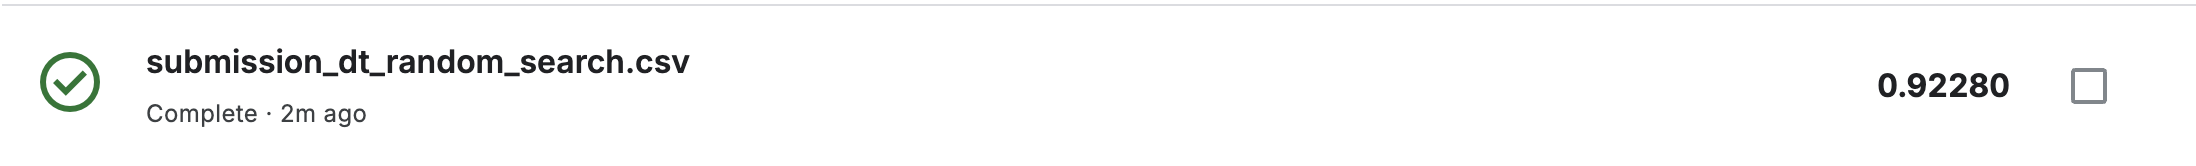